## Exercice 1 :  Reconnaissance de chiffres manuscrits (MNIST)  
L’objectif est de construire un réseau de neurones entièrement 
connecté (Dense) avec TensorFlow/Keras capable de reconnaître 
des chiffres manuscrits (0–9) à partir du jeu de données MNIST.

In [1]:
# importer les bibliotheques 
# permet de constuire et d'entrainer le reseau de neurones
import tensorflow as tf 
# sequential permet de creer le reseau de neurone 
# en placant les couches les unes apres les autres dans un ordre precis 
from tensorflow.keras import Sequential
# importer les types des couches 
from tensorflow.keras.layers import Input, Dense, Flatten
# dataset MNIST des images des chiffres ecrits a la main
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.20.0


* La difference entre TensorFlow et Keras :
   1. TensorFlow est une bibliotheque qui fournit les outils de calcul necessaires pour construire et entraîner des modeles de Machine Learning et de Deep Learning .
   2. Keras : est une interface haut niveau qui facilite la creation des reseaux de neurones .
* La couche Flatten : transformer l'image (matrice 784 pixels ) en vecteur ( une seule dimension -- une liste de  784 valeurs)
* La couche Input : definir la forme des donnees ( des images de taille 28x28 pixels)
* La couche Dence : est une couche dans laquelle chaque neurone est connecté à toutes les sorties de la couche précédente
* Sequential :sequential permet de creer le reseau de neurone  en placant les couches les unes apres les autres dans un ordre precis  
* TensorFlow version: 2.20.0


In [2]:
# Chargement de dataset MNIST par internet via mnist.load_data()
# x_train : images d'entrainement (60000 images de 28x28 pixels)
# y_train : labels d'entrainement (60000 labels de 0 à 9)
# ( x_test , y_test ) donnees pour evaluation de reseau
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# shape dimension (?images , ? hauteur , ? largeur)
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)
print("y_test shape:", y_test.shape)

x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)
y_test shape: (10000,)


In [3]:
# Normalisation des donnees entre 0 et 1 pour accelerer la convergence 
# chaque pixel a des valeurs entre 0 et 255 avec 0 = noir et 255 = blanche 
x_train = x_train / 255.0
x_test = x_test / 255.0

print("Valeur max f x_train:", x_train.max())  
print("Type dyal x_train:", x_train.dtype)     

Valeur max f x_train: 1.0
Type dyal x_train: float64


* On normalise les valeurs des pixels car les valeurs de chaque pixel sont comprises entre 0 et 225 , donc oon normalise les pixels entre 0 et 1 pour faciliter les calculs et l'apprentissage 
* La taille des images : 28x28 pixels , son type de donnees  : entiers entre 0 et 255 et apres normalisation est de type float64
* Le jeu d'entrainement contient 60000 exemples 

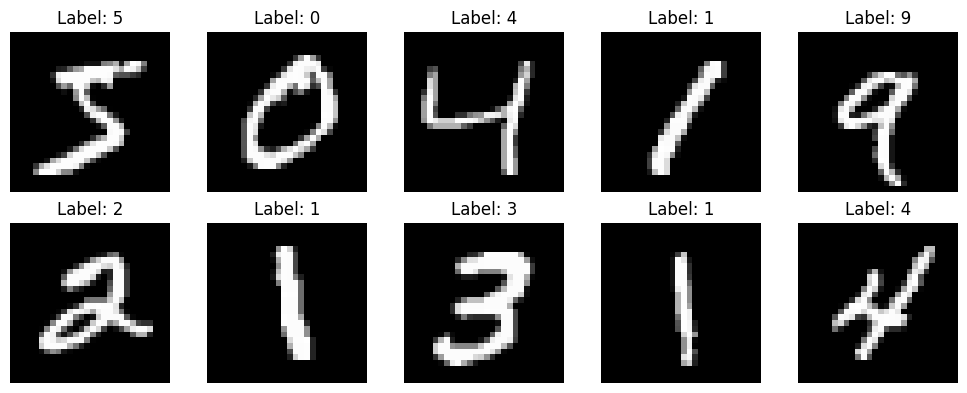

In [4]:
# Visualisation 
plt.figure(figsize=(10, 4))
for i in range(10):
    # divise l'image en 2 lignes et 5 colonnes et affiche la i-eme image
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}") # bonne reponse 
    plt.axis('off') # supprime les axes 
plt.tight_layout()
plt.show()

1. Quelle commande permet de modifier le nombre d’images affichées ?
range(10) permet d'afficher 10 images. On peut modifier 10 pour changer leur nombre, en adaptant aussi plt.subplot() .

2. l’argument cmap='gray' = affiche les images en niveaux de gris, sans couleurs.

3. Quelle utilité a cette étape dans un projet d’IA ?
Elle permet de visualiser les données, de vérifier les images et leurs labels avant d’entraîner le modèle.

In [5]:
model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

1. Combien de paramètres le modèle contient-il ?
- Flatten() : 0 paramètre.
- Dense(128) : \(784 \times 128 + 128 = 100\,480\).
- Dense(10) : \(128 \times 10 + 10 = 1\,290\).
Total : 101 770 paramètres entraînables.
2. Quelle est la fonction d’activation utilisée dans la couche de sortie ? Pourquoi ?

Softmax : elle transforme les sorties en probabilités prédites pour les 10 classes (chiffres de 0 à 9), afin de choisir le chiffre le plus probable.

3. Quelle est la différence entre ReLU et Softmax ?
- ReLU : utilisée dans la couche cachée, elle introduit de la non-linéarité en remplaçant les valeurs négatives par 0.
- Softmax : utilisée dans la couche de sortie, elle transforme les scores en probabilités dont la somme vaut 1.

In [6]:
# Compilation de Modele 
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

1. Qu’est-ce qu’un optimiseur ?
C’est un algorithme qui ajuste les paramètres du réseau pour réduire l’erreur. Exemple : adam.

2. Pourquoi utilise-t-on une fonction de perte (loss) ?
Pour mesurer l’écart entre les prédictions du modèle et les bonnes réponses.

3. Que se passe-t-il si on change la fonction de perte ?
La manière de calculer l’erreur change, ce qui peut modifier l’apprentissage du modèle.

4. Quelle serait la conséquence d’un mauvais choix d’optimiseur ?
L’apprentissage peut être lent, instable ou ne pas converger correctement.

5. Quelle est la différence entre loss et metrics ?
- loss : mesure l’erreur utilisée pour guider l’apprentissage.
- metrics : mesure les performances du modèle. Ici, accuracy représente le pourcentage de prédictions correctes.

In [7]:
# Entrainement 
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=32,
    validation_data=(x_test, y_test)
)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 27s 12ms/step - accuracy: 0.9252 - loss: 0.2625 - val_accuracy: 0.9581 - val_loss: 0.1386
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 10ms/step - accuracy: 0.9667 - loss: 0.1138 - val_accuracy: 0.9707 - val_loss: 0.0989
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 10ms/step - accuracy: 0.9771 - loss: 0.0775 - val_accuracy: 0.9740 - val_loss: 0.0860
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 9ms/step - accuracy: 0.9831 - loss: 0.0570 - val_accuracy: 0.9753 - val_loss: 0.0811
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 8ms/step - accuracy: 0.9866 - loss: 0.0455 - val_accuracy: 0.9778 - val_loss: 0.0686


## À observer
- La précision d’entraînement augmente-t-elle ? Généralement oui, le modèle apprend progressivement.
- La précision de validation suit-elle la même tendance ? Elle peut augmenter aussi, mais elle peut diminuer si le modèle surapprend.
## Questions
1. Que représente une époque (epoch) ?
Un passage complet du modèle sur toutes les données d’entraînement.

2. Pourquoi utilise-t-on un jeu de validation ?
Pour évaluer les performances du modèle sur des données non utilisées pour ajuster ses paramètres et détecter le surapprentissage.

3. Que se passerait-il si on augmentait le nombre d’époques à 50 ?
Le modèle pourrait mieux apprendre, mais il risque aussi de faire du surapprentissage (overfitting) : la précision d’entraînement augmente tandis que celle de validation  diminue.

In [8]:
# Evaluation de modele 
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.9778 - loss: 0.0686
Test accuracy: 0.9778
Test loss: 0.0686


1. Quelle est la précision finale du modèle ?
Elle est donnée par test_acc. La valeur exacte dépend du résultat obtenu lors de l'exécution du code.

2. Pourquoi la précision du test est-elle souvent inférieure à celle d’entraînement ?
Parce que le modèle a appris sur les données d’entraînement et peut moins bien généraliser à de nouvelles données.

3. Que faire si le modèle surapprend (overfitting) ?
- Réduire le nombre d’époques.
- Ajouter une régularisation (Dropout).
- Utiliser davantage de données d’entraînement.
- Arrêter l’entraînement lorsque les performances de validation commencent à se dégrader.

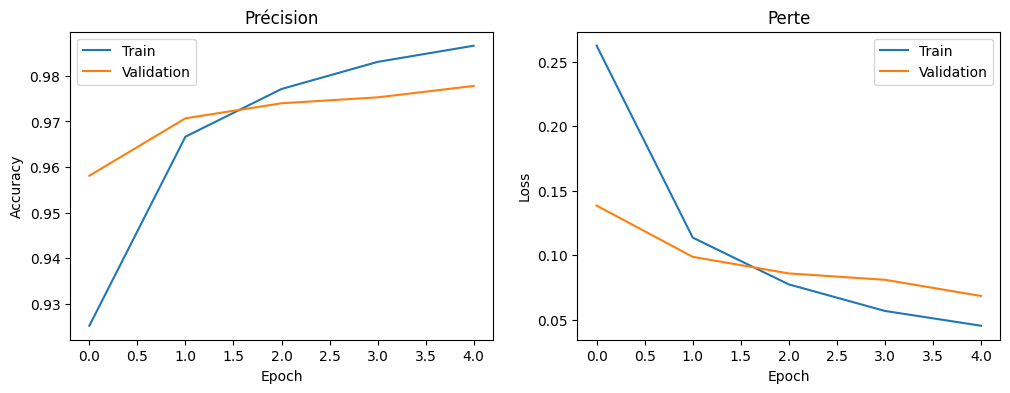

In [9]:
# Visualisation des performances 
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Précision')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Perte')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

1. Que remarquez-vous sur les deux courbes ?
La précision (accuracy) augmente généralement et la perte (loss) diminue pendant l’entraînement.

2. Comment détecter visuellement un surapprentissage ?
La précision d’entraînement continue d’augmenter, tandis que celle de validation stagne ou diminue. La perte de validation augmente alors que la perte d’entraînement diminue.

3. Quelle stratégie pourrait-on utiliser pour y remédier ?
Réduire le nombre d’époques, utiliser Dropout ou appliquer l’arrêt anticipé (Early Stopping).

4. Que faire si les deux courbes divergent ?
Vérifier le surapprentissage, puis ajuster l’entraînement (nombre d’époques, régularisation et données). Si les deux courbes s’améliorent ensemble, il n’y a pas nécessairement de problème.

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


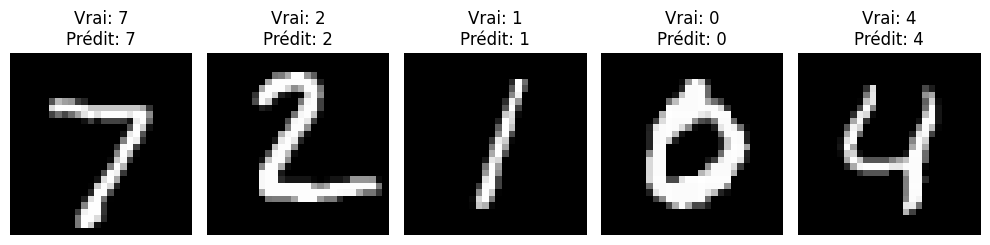

In [10]:
# Predictions et Visualisation
predictions = model.predict(x_test)

plt.figure(figsize=(10, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    plt.title(f"Vrai: {y_test[i]}\nPrédit: {np.argmax(predictions[i])}")
    plt.axis('off')
plt.tight_layout()
plt.show()

1. Le modèle fait-il des erreurs ? Sur quelles images ?
Oui, si le chiffre prédit (Prédit) est différent du vrai chiffre (Vrai). Les images concernées sont celles où les deux valeurs diffèrent.

2. Comment expliquer une prédiction erronée ?
L’image peut être difficile à reconnaître, ambiguë ou différente des exemples appris par le modèle.

3. Quelle technique permettrait d’améliorer la précision ?
Utiliser un CNN (Convolutional Neural Network), mieux adapté à la reconnaissance d’images, car il apprend à détecter des caractéristiques spatiales comme les contours et les formes des chiffres.